# 확률 분포와 손실 함수의 수학적 기반

손실 함수는 임의로 고른 공식이 아니다. **"데이터가 어떤 확률 분포에서 나왔다고 가정하는가"**를 정하면 최대우도추정(MLE)이 손실 함수를 결정한다.

| 순서 | 내용 |
| --- | --- |
| 1 | 정규분포 PDF 2종, 베르누이 PMF 2종 시각화 |
| 2 | 소프트맥스 구현과 합 = 1 검증 |
| 3 | MSE 최소화 = 정규분포 가정의 MLE |
| 4 | Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정의 MLE |
| 5 | 두 손실의 기울기 비교 |
| 6 | (보너스) 엔트로피 · KL-Divergence · Cross-Entropy |

코드 셀의 주석은 Python 문법과 배열 shape을 설명한다. 함수별 데이터 흐름과 작은 숫자 예제는 [코드 읽기 가이드](../study/code-walkthrough.md)에 있다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# notebooks/에서 열든 프로젝트 루트에서 열든 src를 import할 수 있게 한다.
# (sys.path와 set_printoptions의 뜻은 backprop_derivation.ipynb 첫 코드 셀 주석 참고)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
np.random.seed(42)
np.set_printoptions(precision=6, suppress=True)

from src import probability as prob
from src import information as info

## 1. 확률 분포 시각화

### 정규분포 $\mathcal N(\mu, \sigma^2)$

$$
p(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\Big(-\frac{(x-\mu)^2}{2\sigma^2}\Big)
$$

표기 $\mathcal N(\mu, \sigma^2)$의 두 번째 값은 **분산**이다. 그래서 $\mathcal N(2, 0.5)$는 $\sigma = \sqrt{0.5} \approx 0.707$이다. 폭이 좁아진 만큼 봉우리가 높아져 넓이는 항상 1이다. 연속 분포의 PDF 값은 확률이 아니라 밀도이므로 1보다 클 수도 있다.

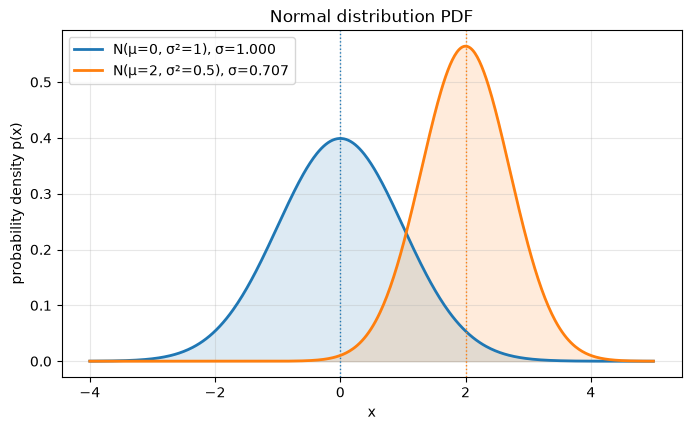

N(0, 1): 최대 밀도 0.3989, 넓이 1.000000
N(2, 0.5): 최대 밀도 0.5642, 넓이 1.000000


In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
prob.plot_normal_pdfs(((0.0, 1.0), (2.0, 0.5)), ax)
plt.show()

# 넓이 = 1인지 숫자로 확인한다. 아주 촘촘한 x에서 "높이 × 폭"인 직사각형 넓이를 모두 더한다(리만 합).
# x는 −10~12를 20001개로 나눈 점, x[1] − x[0]은 한 칸의 폭 0.0011이다.
x = np.linspace(-10, 12, 20001)
for mu, var in ((0, 1), (2, 0.5)):
    area = np.sum(prob.normal_pdf(x, mu, var)) * (x[1] - x[0])
    print(f"N({mu}, {var}): 최대 밀도 {prob.normal_pdf(mu, mu, var):.4f}, 넓이 {area:.6f}")

### 베르누이 분포 $\mathrm{Bernoulli}(p)$

$$
P(X=k) = p^k (1-p)^{1-k}, \qquad k \in \{0, 1\}
$$

한 번의 예/아니오 결과를 나타낸다. 이진 분류 모델의 출력 $\hat y$를 "정답이 1일 확률 $p$"로 해석한다.

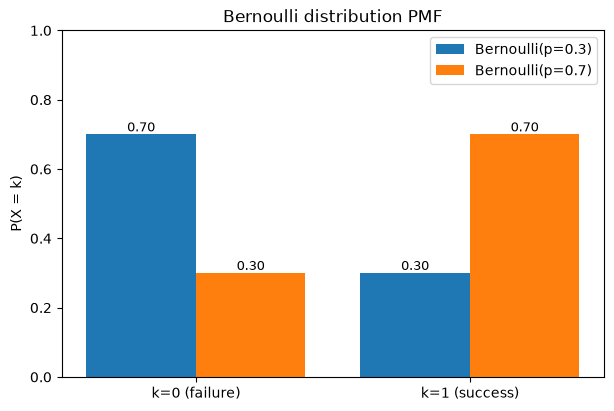

B(0.3): P(0)=0.7, P(1)=0.3
B(0.7): P(0)=0.3, P(1)=0.7


In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
prob.plot_bernoulli_pmfs((0.3, 0.7), ax)
plt.show()
# bernoulli_pmf(0, p)는 0이 나올 확률 1 − p, bernoulli_pmf(1, p)는 1이 나올 확률 p.
for p in (0.3, 0.7):
    print(f"B({p}): P(0)={prob.bernoulli_pmf(0, p):.1f}, P(1)={prob.bernoulli_pmf(1, p):.1f}")

## 2. 소프트맥스

여러 클래스의 점수(logit) $z$를 확률 분포로 바꾼다.

$$
\mathrm{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}
$$

모든 성분이 양수이고 합이 1이다. 모든 $z_i$에서 같은 상수 $c$를 빼도 분자와 분모에 $e^{-c}$가 곱해져 결과가 같다. 그래서 $c = \max z$를 빼서 $e^{1000}$ 같은 overflow를 막는다.

In [4]:
# randn(5)는 표준정규 난수 5개 (5,). × 3으로 점수 차이를 키운다.
logits = np.random.randn(5) * 3
s = prob.softmax(logits)
print("logits :", np.round(logits, 4))
print("softmax:", np.round(s, 4))
print(f"합 - 1 = {abs(s.sum() - 1):.2e}")
assert abs(s.sum() - 1) < 1e-6

big = np.array([1000.0, 1001.0, 1002.0])
# 안정화 없이 계산하면 e^1000이 inf(무한대)가 되고 inf / inf = nan이 된다.
# errstate(...)는 이 블록 안에서만 overflow 경고를 숨긴다. 결과가 망가지는 것을 보여 주려는 것이다.
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(big) / np.exp(big).sum()
print("\n최댓값을 빼지 않은 계산:", naive)
print("안정화한 softmax       :", prob.softmax(big), "합", prob.softmax(big).sum())

# (4, 6) 배열: 샘플 4개 × 클래스 6개. axis=1로 행(샘플)마다 softmax하고, 행마다 더하면 (4,)가 모두 1이다.
batch = np.random.randn(4, 6) * 50
print("\n배치 (4, 6) 각 행의 합:", prob.softmax(batch, axis=1).sum(axis=1))
assert np.allclose(prob.softmax(batch, axis=1).sum(axis=1), 1.0, atol=1e-6)

logits : [ 1.4901 -0.4148  1.9431  4.5691 -0.7025]
softmax: [0.0407 0.0061 0.064  0.8847 0.0045]
합 - 1 = 0.00e+00

최댓값을 빼지 않은 계산: [nan nan nan]
안정화한 softmax       : [0.090031 0.244728 0.665241] 합 0.9999999999999999

배치 (4, 6) 각 행의 합: [1. 1. 1. 1.]


## 3. MSE 최소화 = 정규분포 가정의 MLE

**가정.** 관측값은 모델 예측에 정규 잡음이 더해진 것이다.

$$
y_i = f(x_i) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal N(0, \sigma^2) \quad\Longrightarrow\quad
p(y_i \mid x_i) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\Big(-\frac{(y_i - f(x_i))^2}{2\sigma^2}\Big)
$$

**우도.** 샘플이 서로 독립이면 전체 데이터의 확률은 곱이다. 곱은 다루기 어렵고 작은 값이 계속 곱해져 0에 가까워진다. 그래서 단조 증가 함수인 log를 씌워 합으로 바꾼다. 최대가 되는 위치는 그대로다.

$$
\hat\theta_{\text{MLE}} = \arg\max_\theta \prod_{i=1}^n p(y_i \mid x_i;\theta) = \arg\max_\theta \sum_{i=1}^n \log p(y_i \mid x_i;\theta)
$$

**대입.**

$$
\sum_{i=1}^n \log p(y_i\mid x_i) = \sum_{i=1}^n \Big[-\frac{(y_i - f(x_i))^2}{2\sigma^2} - \frac12\log(2\pi\sigma^2)\Big]
= -\frac{1}{2\sigma^2}\sum_{i=1}^n (y_i - f(x_i))^2 - \frac n2 \log(2\pi\sigma^2)
$$

**상수 제거.** $\sigma^2$가 고정이면 두 번째 항은 $\theta$와 무관하다. 양수 $\frac{1}{2\sigma^2}$, $\frac1n$을 곱하거나 나눠도 최적점은 변하지 않는다. 부호를 바꾸면 max가 min이 된다.

$$
\arg\max_\theta \sum \log p = \arg\min_\theta \sum_{i=1}^n (y_i - f(x_i))^2 = \arg\min_\theta \underbrace{\frac1n\sum_{i=1}^n (y_i - f(x_i))^2}_{\text{MSE}}
$$

**결론.** 잡음이 정규분포라고 가정한 MLE는 MSE 최소화와 같다. 반대로 MSE를 쓰면 정규 잡음을 가정한 것이다. 이상치가 많은 두꺼운 꼬리 잡음에서는 이 가정이 맞지 않는다. 라플라스 분포를 가정하면 MAE가 나온다.

argmin MSE = 1.505, argmin NLL = 1.505, 닫힌 해 Σxy/Σx² = 1.505

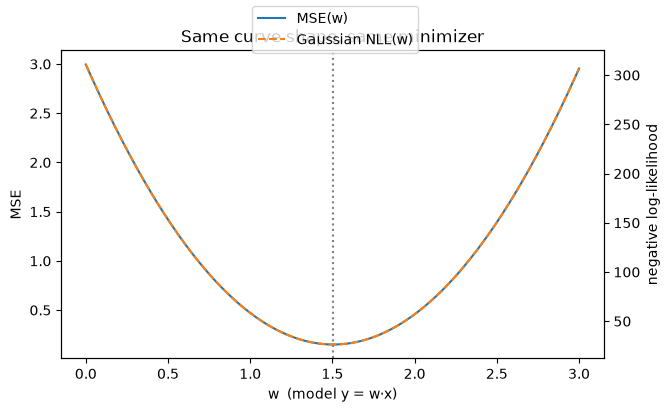

In [5]:
# 설명용 합성 데이터. default_rng(42)는 재현 가능한 난수 생성기다.
rng = np.random.default_rng(42)
x = rng.uniform(-2, 2, 50)                    # −2~2 균등분포 50개 (50,)
y = 1.5 * x + rng.normal(0, 0.5, 50)     # 실제 w = 1.5, σ = 0.5
var = 0.25

# w 후보 601개를 모두 대입해 보는 격자 탐색. [식 for w in ws]로 w마다 손실을 계산해 (601,) 배열로 만든다.
ws = np.linspace(0, 3, 601)
mse_curve = np.array([prob.mse(y, w * x) for w in ws])
nll_curve = np.array([prob.gaussian_nll(y, w * x, var) for w in ws])

# NLL = n/(2σ²)·MSE + (n/2)·log(2πσ²) 를 모든 w에서 확인한다.
# 양수배 + 상수라서 두 곡선의 최소 위치(argmin)는 반드시 같다.
n = len(x)
assert np.allclose(nll_curve, n / (2 * var) * mse_curve + n / 2 * np.log(2 * np.pi * var))
# argmin()은 가장 작은 값의 위치(번호). ws[그 번호]가 최적 w다.
print(f"argmin MSE = {ws[mse_curve.argmin()]:.3f}, argmin NLL = {ws[nll_curve.argmin()]:.3f}, "
      f"닫힌 해 Σxy/Σx² = {np.dot(x, y) / np.dot(x, x):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ws, mse_curve, label="MSE(w)")
# twinx: 오른쪽에 두 번째 y축. 크기가 다른 두 곡선의 모양만 겹쳐 비교한다.
ax2 = ax.twinx()
ax2.plot(ws, nll_curve, "--", color="tab:orange", label="Gaussian NLL(w)")
ax.axvline(ws[mse_curve.argmin()], color="gray", ls=":")
ax.set_xlabel("w  (model y = w·x)")
ax.set_ylabel("MSE")
ax2.set_ylabel("negative log-likelihood")
ax.set_title("Same curve shape, same minimizer")
fig.legend(loc="upper center")
plt.show()

## 4. Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정의 MLE

### 이진 분류 — 베르누이

**가정.** 정답 $y_i \in \{0,1\}$은 모델이 출력한 확률 $\hat y_i = \sigma(z_i)$를 갖는 베르누이 분포에서 나온다.

$$
p(y_i \mid x_i) = \hat y_i^{\,y_i}\,(1-\hat y_i)^{1-y_i}
$$

$y_i=1$이면 $\hat y_i$, $y_i=0$이면 $1-\hat y_i$가 남는다. 두 경우를 지수로 한 식에 담은 것이다.

**로그우도.**

$$
\sum_{i=1}^n \log p(y_i\mid x_i) = \sum_{i=1}^n \big[\,y_i \log \hat y_i + (1-y_i)\log(1-\hat y_i)\,\big]
$$

**부호를 바꾸면** 그대로 Binary Cross-Entropy다. 상수를 버리는 과정도 필요 없다.

$$
\arg\max_\theta \sum \log p = \arg\min_\theta \; -\sum_{i=1}^n \big[\,y_i \log \hat y_i + (1-y_i)\log(1-\hat y_i)\,\big] = \arg\min_\theta \mathrm{BCE}
$$

### 다중 분류 — 카테고리 분포

클래스가 $C$개이고 정답이 one-hot 벡터 $y_i$, 모델 확률이 $\hat y_i = \mathrm{softmax}(z_i)$일 때

$$
p(y_i\mid x_i) = \prod_{c=1}^C \hat y_{ic}^{\,y_{ic}}
\quad\Longrightarrow\quad
-\sum_i \log p(y_i\mid x_i) = -\sum_{i}\sum_{c} y_{ic}\log \hat y_{ic} = \text{Categorical Cross-Entropy}
$$

one-hot이므로 실제로는 **정답 클래스 확률의 $-\log$**만 남는다. $C=2$이면 베르누이 경우와 같다.

In [6]:
# 이진: BCE 합 == -log(베르누이 우도의 곱)
y_true = np.array([1, 0, 1, 1, 0])
p_pred = np.array([0.9, 0.2, 0.6, 0.4, 0.1])
# bernoulli_pmf(y_true, p_pred)는 샘플마다 "실제 정답이 나올 확률" [0.9, 0.8, 0.6, 0.4, 0.9] (5,).
# np.prod는 모두 곱한 값(우도)이다.
likelihood = np.prod(prob.bernoulli_pmf(y_true, p_pred))
print(f"베르누이 우도 Π p = {likelihood:.6f}")
print(f"-log(우도)        = {-np.log(likelihood):.6f}")
print(f"BCE 합            = {prob.bernoulli_nll(y_true, p_pred):.6f}")
assert np.isclose(-np.log(likelihood), prob.bernoulli_nll(y_true, p_pred))

# 다중: Categorical CE == 정답 클래스 softmax 확률의 -log 합
# logits (2, 3): 샘플 2개 × 클래스 3개. onehot은 정답 칸만 1 (샘플 0의 정답은 클래스 0, 샘플 1은 클래스 1).
logits = np.array([[2.0, 1.0, 0.1], [0.5, 2.5, 0.3]])
onehot = np.array([[1, 0, 0], [0, 1, 0]])
probs = prob.softmax(logits)
# probs[0, 0]은 0행 0열 = 샘플 0의 정답 확률, probs[1, 1]은 샘플 1의 정답 확률.
manual = -np.log(probs[0, 0]) - np.log(probs[1, 1])
print(f"\nsoftmax 확률:\n{np.round(probs, 4)}")
print(f"Categorical CE = {prob.categorical_cross_entropy(onehot, logits):.6f}, 정답 확률 -log 합 = {manual:.6f}")
assert np.isclose(prob.categorical_cross_entropy(onehot, logits), manual)

# 두 클래스 softmax == sigmoid: softmax([z, 0])[0] = σ(z)
z = 0.8
print(f"\nsoftmax([z,0])[0] = {prob.softmax(np.array([z, 0.0]))[0]:.6f}, σ(z) = {1 / (1 + np.exp(-z)):.6f}")

베르누이 우도 Π p = 0.155520
-log(우도)        = 1.860981
BCE 합            = 1.860981

softmax 확률:
[[0.659  0.2424 0.0986]
 [0.1086 0.8025 0.0889]]
Categorical CE = 0.637080, 정답 확률 -log 합 = 0.637080

softmax([z,0])[0] = 0.689974, σ(z) = 0.689974


In [7]:
# 로지스틱 모델 p = σ(w·x)에서 BCE 최소점 == 우도 최대점
rng = np.random.default_rng(7)
x = rng.uniform(-2, 2, 60)
# (난수 < 확률)은 그 확률로 True가 된다. astype(int)로 True/False를 1/0 정답으로 바꾼다.
yb = (rng.uniform(size=60) < 1 / (1 + np.exp(-2 * x))).astype(int)   # 실제 w = 2
ws = np.linspace(0, 4, 801)
bce = np.array([prob.bernoulli_nll(yb, 1 / (1 + np.exp(-w * x))) for w in ws])
lik = np.array([np.prod(prob.bernoulli_pmf(yb, 1 / (1 + np.exp(-w * x)))) for w in ws])
print(f"argmin BCE = {ws[bce.argmin()]:.3f}, argmax likelihood = {ws[lik.argmax()]:.3f}")
# 같은 격자 위의 같은 칸을 골라야 하므로 == 로 정확히 비교한다.
assert ws[bce.argmin()] == ws[lik.argmax()]

argmin BCE = 2.090, argmax likelihood = 2.090

## 5. 왜 분류에 MSE 대신 Cross-Entropy를 쓰는가

출력이 $\hat y = \sigma(z)$인 이진 분류에서 logit $z$에 대한 기울기를 비교한다.

$$
\frac{\partial\,\mathrm{BCE}}{\partial z} = \hat y - y, \qquad
\frac{\partial\,\tfrac12(\hat y - y)^2}{\partial z} = (\hat y - y)\,\hat y(1-\hat y)
$$

MSE 쪽에는 $\sigma'(z) = \hat y(1-\hat y)$가 곱해진다. 모델이 **확신을 갖고 틀린 경우**(예: $y=1$인데 $\hat y \approx 0$)에는 이 값이 0에 가까워 학습이 거의 멈춘다. BCE는 이 항이 약분되어 크게 틀릴수록 기울기도 크다. 역전파 노트북의 $\partial L/\partial z_2 = \hat y - y$와 같은 식이다.

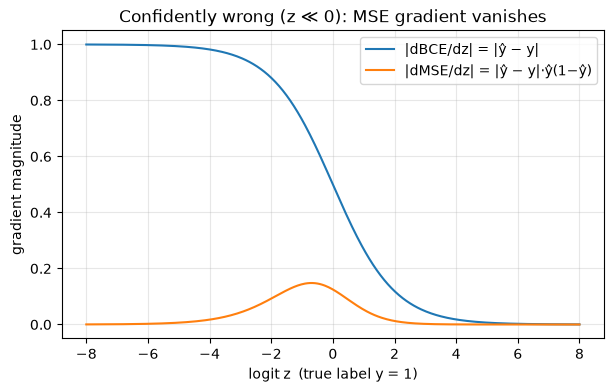

z=-6 (ŷ=0.0025): BCE 기울기 0.9975, MSE 기울기 0.0025


In [8]:
# z: logit −8~8의 400개 점 (400,). 아래 계산은 모두 원소별이라 결과도 (400,)이다.
z = np.linspace(-8, 8, 400)
y_hat = 1 / (1 + np.exp(-z))
y = 1.0
grad_bce = y_hat - y
grad_mse = (y_hat - y) * y_hat * (1 - y_hat)

plt.figure(figsize=(7, 4))
plt.plot(z, np.abs(grad_bce), label="|dBCE/dz| = |ŷ − y|")
plt.plot(z, np.abs(grad_mse), label="|dMSE/dz| = |ŷ − y|·ŷ(1−ŷ)")
plt.xlabel("logit z  (true label y = 1)")
plt.ylabel("gradient magnitude")
plt.title("Confidently wrong (z ≪ 0): MSE gradient vanishes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
# np.argmin(abs(z + 6)): z가 −6에 가장 가까운 칸의 번호. 그 칸의 두 기울기를 비교한다.
print(f"z=-6 (ŷ={1 / (1 + np.exp(6)):.4f}): BCE 기울기 {abs(grad_bce[np.argmin(abs(z + 6))]):.4f}, "
      f"MSE 기울기 {abs(grad_mse[np.argmin(abs(z + 6))]):.4f}")

## 6. (보너스) 정보 이론: 엔트로피 · Cross-Entropy · KL-Divergence

| 개념 | 식 | 의미 |
| --- | --- | --- |
| 엔트로피 | $H(p) = -\sum_i p_i \log p_i$ | 분포 $p$ 자체의 불확실성 |
| Cross-Entropy | $H(p, q) = -\sum_i p_i \log q_i$ | 실제 $p$의 사건을 모델 $q$로 설명할 때의 평균 정보량 |
| KL-Divergence | $\mathrm{KL}(p\,\|\,q) = \sum_i p_i \log \dfrac{p_i}{q_i}$ | $q$로 근사해서 생기는 추가 비용, 항상 ≥ 0 |

$$
H(p, q) = -\sum p_i \log q_i = -\sum p_i \log p_i + \sum p_i \log\frac{p_i}{q_i} = H(p) + \mathrm{KL}(p\,\|\,q)
$$

학습에서 $p$(데이터의 정답 분포)는 고정이므로 $H(p)$는 상수다. 따라서 **Cross-Entropy 최소화 = KL 최소화 = 모델 분포를 데이터 분포에 가깝게 만들기**이고, 이것이 앞에서 본 MLE와 같은 목표다. 단위는 자연로그 기준 nat이다.

H(p)       = 0.8018
H(p, q)    = 0.9856
KL(p ‖ q)  = 0.1838
H(p) + KL  = 0.9856   ← H(p, q)와 같다
KL(q ‖ p)  = 0.1920   ← KL(p ‖ q)와 다르다: 거리 함수처럼 대칭이 아니다
KL(p ‖ p)  = 0.0000
균등분포 4개 엔트로피 = 1.3863 = log 4 = 1.3863 (최대)

one-hot p: H(p)=-0.0000, H(p,q)=0.9163, KL=0.9163, -log q[1]=0.9163


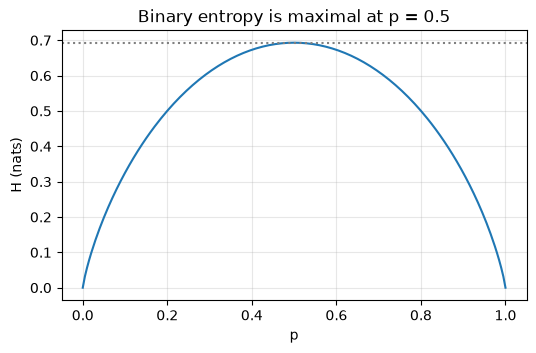

In [9]:
p = np.array([0.7, 0.2, 0.1])
q = np.array([0.4, 0.4, 0.2])
H, CE, KL, KL_rev = info.entropy(p), info.cross_entropy(p, q), info.kl_divergence(p, q), info.kl_divergence(q, p)
print(f"H(p)       = {H:.4f}")
print(f"H(p, q)    = {CE:.4f}")
print(f"KL(p ‖ q)  = {KL:.4f}")
print(f"H(p) + KL  = {H + KL:.4f}   ← H(p, q)와 같다")
print(f"KL(q ‖ p)  = {KL_rev:.4f}   ← KL(p ‖ q)와 다르다: 거리 함수처럼 대칭이 아니다")
print(f"KL(p ‖ p)  = {info.kl_divergence(p, p):.4f}")
# [0.25] * 4는 리스트 반복: [0.25, 0.25, 0.25, 0.25].
print(f"균등분포 4개 엔트로피 = {info.entropy([0.25] * 4):.4f} = log 4 = {np.log(4):.4f} (최대)")

# one-hot 정답이면 H(p)=0이라 Cross-Entropy == KL == -log q[정답]
onehot = np.array([0.0, 1.0, 0.0])
print(f"\none-hot p: H(p)={info.entropy(onehot):.4f}, H(p,q)={info.cross_entropy(onehot, q):.4f}, "
      f"KL={info.kl_divergence(onehot, q):.4f}, -log q[1]={-np.log(q[1]):.4f}")
assert np.isclose(CE, H + KL)

ps = np.linspace(0, 1, 201)
plt.figure(figsize=(6, 3.5))
plt.plot(ps, info.binary_entropy(ps))
plt.axhline(np.log(2), color="gray", ls=":")
plt.xlabel("p")
plt.ylabel("H (nats)")
plt.title("Binary entropy is maximal at p = 0.5")
plt.grid(alpha=0.3)
plt.show()

## 확인 질문

답을 먼저 예측한 뒤 펼쳐 확인한다.

1. `softmax([1, 2, 3])`과 `softmax([101, 102, 103])`의 결과는 같을까?
2. 3절에서 `var = 0.25` 대신 `var = 1`로 NLL 곡선을 그리면 최소가 되는 w는 바뀔까?
3. one-hot 정답 p = [0, 1, 0], 모델 q = [0.4, 0.4, 0.2]일 때 KL(p‖q)는 얼마일까?

<details><summary>답 보기</summary>

1. 같다. 모든 점수에 같은 수를 더하면 분자·분모에 같은 $e^{c}$가 곱해져 약분된다. 둘 다 [0.090, 0.245, 0.665]다.
2. 바뀌지 않는다. NLL = $\frac{n}{2\sigma^2}$·MSE + 상수라서 $\sigma^2$는 곡선의 배율과 높이만 바꾼다.
3. $H(p) = 0$이라 KL = Cross-Entropy = $-\log 0.4 \approx 0.916$이다. 6절 셀의 one-hot 출력과 같다.

</details>

## 정리

- 분포를 가정하면 MLE가 손실을 정한다. 정규 잡음 가정에서는 **MSE**, 베르누이·카테고리 가정에서는 **Cross-Entropy**가 나온다.
- log는 곱을 합으로 바꾸고 최적점을 바꾸지 않는다. 음의 로그우도를 최소화하는 것이 우도를 최대화하는 것이다.
- Cross-Entropy는 $H(p) + \mathrm{KL}(p\|q)$이며, 정답 분포가 고정이면 KL을 줄이는 것과 같다.
- Sigmoid/Softmax + Cross-Entropy 조합의 logit 기울기는 $\hat y - y$로 단순하고, 확신을 갖고 틀린 예측에서도 사라지지 않는다.